# Final circuits: the searched genomes as real quantum circuits

Until now every genome was scored by its classical twin. This notebook trains them as real 8-qubit PennyLane circuits on all FF++ train frames and scores them on FF++ val (video AUC with a 95% bootstrap interval). FF++ test and Celeb-DF are not touched; they come once, in the test notebook.

**Stage A: one circuit per run.** For each backbone, the top genome of every search run (rank 1 by fitness, from `search_analysis`) and the five baselines (first 8 PCA, strongest 8, PLS 8, MI top 8, greedy), trained once (seed 0) with no entangler. This gives every method a real-circuit val number per run, so the method comparison and its statistics can be repeated on real circuits, and it checks the twin against the circuit on val. Genomes found by several runs are trained once.

**Stage B: finalists.** For each backbone, the genome with the best stage A val AUC from each main method (random search, GA, PSO, memetic GA), plus first 8 PCA, PLS 8 and greedy. Each finalist is trained with 5 seeds, without an entangler and with a CZ ring. Because the finalists were picked on the seed 0 val number, their val is also reported as the mean over seeds 1 to 4, which played no part in the choice.

**The circuits.**
- No entangler: encoding, one rotation layer, ⟨Z⟩ on every qubit, then a weighted sum plus a bias. This is the additive circuit the twin describes.
- CZ ring: encoding, a rotation layer, CZ gates around the ring, a second rotation layer, then the same readout. The second rotation layer is needed: CZ commutes with a Z measurement, so a CZ ring right before the readout would change nothing.

Training as in Phase 1's final circuits: Adam, learning rate 0.01, 5 epochs, batch 256, BCE loss, `default.qubit` with backprop, float64.

The plan said the top 3 genomes per run. That would be about 3,600 trainings; this design gives the same answers with about 350, which fits a Kaggle session per backbone. `top_genomes.csv` still holds ranks 2 and 3.

Every training is written to `trainings.jsonl` as soon as it finishes, with its weights in `weights/`. A stopped session resumes from this notebook's earlier output: attach it as an input and run again.

## 1. Settings

In [1]:
smoke = False             
backbones = ["l14", "b16", "effb4"]
main_methods = ["random", "GA", "PSO", "memetic GA"]
descriptive_methods = ["DE", "GWO"]
final_baselines = ["first 8 PCA", "PLS 8", "greedy"]
seeds = [0, 1, 2, 3, 4]
entanglers = ["none", "CZ ring"]
lr = 0.01
epochs = 5
batch_size = 256
n_boot = 1000
n_jobs = 0                
machine_name = "kaggle"
seed = 0
out_dir = "/kaggle/working/final_circuits"

train_limit = None          
if smoke:
    train_limit = 2000
    epochs = 1
    seeds = [0, 1]
    out_dir += "_smoke"

In [2]:
!pip install -q pennylane

## 2. Imports

In [3]:
import os
os.environ["OMP_NUM_THREADS"] = "1"
import glob
import json
import shutil
import time
import platform
import multiprocessing as mp
import numpy as np
import pandas as pd
import scipy
import sklearn
import torch
import pennylane as qml
import matplotlib.pyplot as plt
from scipy.stats import kruskal, mannwhitneyu, spearmanr
from sklearn.metrics import roc_auc_score

os.makedirs(f"{out_dir}/weights", exist_ok=True)
if n_jobs == 0:
    n_jobs = os.cpu_count()
print("smoke", smoke, "| backbones", backbones, "| jobs", n_jobs, "| pennylane", qml.__version__, "| torch", torch.__version__)

smoke False | backbones ['l14', 'b16', 'effb4'] | jobs 4 | pennylane 0.45.1 | torch 2.11.0+cpu


## 3. Loading


In [4]:
def find_all(filename):
    return sorted(glob.glob("/kaggle/input/**/" + filename, recursive=True))


def find_one(filename, folder=None):
    hits = find_all(filename)
    if folder is not None:
        hits = [p for p in hits if os.path.basename(os.path.dirname(p)) == folder]
    assert len(hits) == 1, (filename, folder, hits)
    return hits[0]


top_genomes = pd.read_csv(find_one("top_genomes.csv", "search_analysis"))
twin_val = pd.read_csv(find_one("val_results.csv", "search_analysis"))
baseline_table = pd.read_csv(find_one("baselines.csv", "search_analysis"))
probe = None
hits = find_all("bottleneck_table.csv")
if len(hits) > 0:
    probe = pd.read_csv(hits[0]).set_index(["backbone", "input"])["val"]

D = {}


def load_backbone(b):
    D.clear()
    pool_dir = os.path.dirname(find_one(f"{b}_ffpp_train_pool.npy"))
    train = np.load(f"{pool_dir}/{b}_ffpp_train_pool.npy").astype(np.float64)
    val = np.load(f"{pool_dir}/{b}_ffpp_val_pool.npy").astype(np.float64)
    rows = pd.read_csv(f"{pool_dir}/ffpp_train_rows.csv", dtype={"video_id": str})
    val_rows = pd.read_csv(f"{pool_dir}/ffpp_val_rows.csv", dtype={"video_id": str})
    columns = json.load(open(f"{pool_dir}/columns.json"))
    assert len(train) == len(rows) and len(val) == len(val_rows) and train.shape[1] == len(columns)
    y = rows["label"].to_numpy().astype(np.float64)
    train_index = np.arange(len(train))
    if train_limit is not None:
        train_index = np.random.default_rng(seed).choice(len(train), train_limit, replace=False)

    video = val_rows.groupby(["method", "video_id"]).ngroup().to_numpy()
    n_videos = video.max() + 1
    video_y = np.zeros(n_videos)
    video_y[video] = val_rows["label"].to_numpy()
    boot = np.random.default_rng(seed).integers(0, n_videos, (n_boot, n_videos))
    D.update(backbone=b, columns=columns, train=train[train_index], y=y[train_index], val=val, video=video,
             video_y=video_y, video_count=np.bincount(video, minlength=n_videos), boot=boot)
    print(f"{b}: training on {len(train_index)} frames, val {val.shape[0]} frames in {n_videos} videos")

## 4. The circuit and its training

`train_circuit` trains one genome with one entangler setting and one seed, saves the weights and returns the val score.

In [5]:
n_qubits = 8
angles_per_rotation = {"RY": 1, "RX+RY": 2, "Rot": 3}


def rotation_layer(w, rotation):
    for i in range(n_qubits):
        if rotation == "RY":
            qml.RY(w[i, 0], wires=i)
        elif rotation == "RX+RY":
            qml.RX(w[i, 0], wires=i)
            qml.RY(w[i, 1], wires=i)
        else:
            qml.Rot(w[i, 0], w[i, 1], w[i, 2], wires=i)


def make_qnode(genome, entangler):
    dev = qml.device("default.qubit", wires=n_qubits)

    @qml.qnode(dev, interface="torch", diff_method="backprop")
    def circuit(x, w):
        for i in range(n_qubits):
            if genome["encoding"] == "RX":
                qml.RX(x[:, i], wires=i)
            elif genome["encoding"] == "RY":
                qml.RY(x[:, i], wires=i)
            else:
                qml.Hadamard(wires=i)
                qml.RZ(x[:, i], wires=i)
        rotation_layer(w[0], genome["rotation"])
        if entangler == "CZ ring":
            for i in range(n_qubits):
                qml.CZ(wires=[i, (i + 1) % n_qubits])
            rotation_layer(w[1], genome["rotation"])
        return [qml.expval(qml.PauliZ(i)) for i in range(n_qubits)]

    return circuit


class VQC(torch.nn.Module):
    def __init__(self, genome, entangler):
        super().__init__()
        self.circuit = make_qnode(genome, entangler)
        layers = 2 if entangler == "CZ ring" else 1
        k = angles_per_rotation[genome["rotation"]]
        self.w = torch.nn.Parameter(0.1 * torch.randn(layers, n_qubits, k, dtype=torch.float64))
        self.readout = torch.nn.Linear(n_qubits, 1, dtype=torch.float64)
        torch.nn.init.normal_(self.readout.weight, std=0.1)
        torch.nn.init.zeros_(self.readout.bias)

    def forward(self, x):
        z = torch.stack(self.circuit(x, self.w), dim=-1).to(torch.float64)
        return self.readout(z).squeeze(-1)


def video_auc(p):
    scores = np.bincount(D["video"], weights=p) / D["video_count"]
    auc = roc_auc_score(D["video_y"], scores)
    boot = [roc_auc_score(D["video_y"][i], scores[i]) for i in D["boot"]]
    return auc, np.percentile(boot, 2.5), np.percentile(boot, 97.5)


def weight_file(key, entangler, s):
    name = f"{D['backbone']}_{key}_{entangler}_{s}".replace("|", "_").replace(" ", "_").replace("+", "p")
    return name + ".pt"


def train_circuit(item):
    torch.set_num_threads(1)
    genome, entangler, s = item
    key = genome["key"]
    start = time.time()
    torch.manual_seed(s)
    model = VQC(genome, entangler)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    loss_fn = torch.nn.BCEWithLogitsLoss()
    xt = torch.tensor(D["train"][:, genome["picks"]], dtype=torch.float64)
    yt = torch.tensor(D["y"], dtype=torch.float64)
    gen = torch.Generator().manual_seed(s)
    for epoch in range(epochs):
        order = torch.randperm(len(xt), generator=gen)
        total = 0.0
        for b in range(0, len(xt), batch_size):
            idx = order[b:b + batch_size]
            opt.zero_grad()
            loss = loss_fn(model(xt[idx]), yt[idx])
            loss.backward()
            opt.step()
            total += loss.item() * len(idx)
    with torch.no_grad():
        xv = torch.tensor(D["val"][:, genome["picks"]], dtype=torch.float64)
        prob = torch.cat([torch.sigmoid(model(xv[i:i + 4096])) for i in range(0, len(xv), 4096)]).numpy()
    auc, low, high = video_auc(prob)
    torch.save(model.state_dict(), f"{out_dir}/weights/{weight_file(key, entangler, s)}")
    return {"backbone": D["backbone"], "key": key, "genome": json.dumps({k: genome[k] for k in ("picks", "encoding", "rotation")}),
            "entangler": entangler, "seed": s, "val_auc": auc, "val_low": low, "val_high": high,
            "final_loss": total / len(xt), "seconds": time.time() - start, "smoke": smoke}

## 5. Results store

Every finished training is appended to `trainings.jsonl` (and its weights kept), so a stopped session loses at most the trainings that were running. Earlier results with the same settings are loaded from the inputs, with their weight files.

In [6]:
done = {}
results_path = f"{out_dir}/trainings.jsonl"


def done_key(backbone, key, entangler, s):
    return f"{backbone}|{key}|{entangler}|{s}"


earlier = [p for p in find_all("trainings.jsonl") if os.path.basename(os.path.dirname(p)) == os.path.basename(out_dir)]
for path in earlier + ([results_path] if os.path.exists(results_path) else []):
    folder = os.path.dirname(path)
    with open(path) as f:
        for line in f:
            r = json.loads(line)
            done[done_key(r["backbone"], r["key"], r["entangler"], r["seed"])] = r
    if folder != out_dir:
        for w in glob.glob(f"{folder}/weights/*.pt"):
            if not os.path.exists(f"{out_dir}/weights/{os.path.basename(w)}"):
                shutil.copy(w, f"{out_dir}/weights/")
with open(results_path, "w") as f:
    for r in done.values():
        f.write(json.dumps(r) + "\n")
print("trainings already done:", len(done))


def run_items(items):
    todo = [it for it in items if done_key(D["backbone"], it[0]["key"], it[1], it[2]) not in done]
    print(f"{D['backbone']}: {len(items)} trainings, {len(items) - len(todo)} already done, {len(todo)} to run")
    if len(todo) == 0:
        return
    t0 = time.time()
    with mp.get_context("fork").Pool(n_jobs) as workers, open(results_path, "a") as f:
        for n, r in enumerate(workers.imap_unordered(train_circuit, todo), 1):
            done[done_key(r["backbone"], r["key"], r["entangler"], r["seed"])] = r
            f.write(json.dumps(r) + "\n")
            f.flush()
            if n % 10 == 0 or n == len(todo):
                print(f"  {n}/{len(todo)} done, {(time.time() - t0) / 60:.1f} min")

trainings already done: 0


## 6. Stage A and stage B

Stage A trains every distinct genome once. Stage B then picks the finalists from the stage A val numbers and trains them with all seeds and both entangler settings.

In [7]:
def genome_of(row):
    g = json.loads(row["genome"])
    g["key"] = row["key"]
    return g


roles = []   # one row per (backbone, role, genome): which run or baseline a genome stands for
for b in backbones:
    t = top_genomes[(top_genomes["backbone"] == b) & (top_genomes["rank"] == 1)]
    for _, r in t.iterrows():
        roles.append({"backbone": b, "role": r["method"], "run": r["run"], "key": r["key"], "genome": r["genome"]})
    base = baseline_table[(baseline_table["backbone"] == b) & baseline_table["kept"]]
    for _, r in base.iterrows():
        roles.append({"backbone": b, "role": "baseline: " + r["baseline"], "run": 0, "key": r["key"], "genome": r["genome"]})
roles = pd.DataFrame(roles)

finalists = []
start_all = time.time()
for b in backbones:
    load_backbone(b)
    r = roles[roles["backbone"] == b]
    genomes = {k: genome_of(row) for k, row in r.drop_duplicates("key").set_index("key", drop=False).iterrows()}
    run_items([(g, "none", seeds[0]) for g in genomes.values()])

    stage_a = r.copy()
    stage_a["val_auc"] = [done[done_key(b, k, "none", seeds[0])]["val_auc"] for k in stage_a["key"]]
    picks = []
    for m in main_methods:
        best = stage_a[stage_a["role"] == m].sort_values("val_auc", ascending=False).iloc[0]
        picks.append({"backbone": b, "finalist": m, "key": best["key"], "picked_val_seed0": best["val_auc"]})
    for name in final_baselines:
        row = stage_a[stage_a["role"] == "baseline: " + name].iloc[0]
        picks.append({"backbone": b, "finalist": name, "key": row["key"], "picked_val_seed0": row["val_auc"]})
    finalists += picks
    keys = list(dict.fromkeys(p["key"] for p in picks))
    run_items([(genomes[k], e, s) for k in keys for e in entanglers for s in seeds])

finalists = pd.DataFrame(finalists)
trainings = pd.DataFrame([r for r in done.values() if r["backbone"] in backbones])
trainings.to_csv(f"{out_dir}/trainings.csv", index=False)
finalists.to_csv(f"{out_dir}/finalists.csv", index=False)
print("all trainings done in %.1f min, %.0f s per training on average"
      % ((time.time() - start_all) / 60, trainings["seconds"].mean()))

l14: training on 46076 frames, val 22396 frames in 700 videos
l14: 52 trainings, 0 already done, 52 to run
  10/52 done, 4.7 min
  20/52 done, 8.7 min
  30/52 done, 12.9 min
  40/52 done, 16.6 min
  50/52 done, 20.5 min
  52/52 done, 20.8 min
l14: 60 trainings, 6 already done, 54 to run
  10/54 done, 5.5 min
  20/54 done, 10.5 min
  30/54 done, 15.5 min
  40/54 done, 20.2 min
  50/54 done, 25.5 min
  54/54 done, 27.4 min
b16: training on 46076 frames, val 22396 frames in 700 videos
b16: 54 trainings, 0 already done, 54 to run
  10/54 done, 4.6 min
  20/54 done, 8.7 min
  30/54 done, 13.4 min
  40/54 done, 16.8 min
  50/54 done, 20.7 min
  54/54 done, 21.9 min
b16: 70 trainings, 7 already done, 63 to run
  10/63 done, 5.4 min
  20/63 done, 10.6 min
  30/63 done, 17.2 min
  40/63 done, 22.1 min
  50/63 done, 27.4 min
  60/63 done, 32.2 min
  63/63 done, 33.6 min
effb4: training on 46076 frames, val 22396 frames in 700 videos
effb4: 54 trainings, 0 already done, 54 to run
  10/54 done, 5.

## 7. Stage A: methods with real circuits

The val AUC of each run's top genome as a real circuit (no entangler, seed 0), next to the same genome's twin val number from `search_analysis`. Then the statistics of `search_analysis` repeated on the circuit numbers: Kruskal-Wallis across the main methods, Holm-corrected Mann-Whitney against random search, and A12.

In [8]:
stage_a = roles.copy()
stage_a["circuit val"] = [done[done_key(b, k, "none", seeds[0])]["val_auc"] for b, k in zip(stage_a["backbone"], stage_a["key"])]
twin_lookup = twin_val.drop_duplicates(["backbone", "key"]).set_index(["backbone", "key"])["val_auc"]
stage_a["twin val"] = [twin_lookup.get((b, k), np.nan) for b, k in zip(stage_a["backbone"], stage_a["key"])]
stage_a.drop(columns=["genome"]).to_csv(f"{out_dir}/stage_a.csv", index=False)

methods = main_methods + descriptive_methods
runs = stage_a[stage_a["role"].isin(methods)]
ref = stage_a[stage_a["role"].str.startswith("baseline")].set_index(["backbone", "role"])["circuit val"]

table = []
for b in backbones:
    for m in methods:
        r = runs[(runs["backbone"] == b) & (runs["role"] == m)]
        table.append({"backbone": b, "method": m, "runs": len(r), "circuit val mean": r["circuit val"].mean(),
                      "circuit val sd": r["circuit val"].std(), "twin val mean": r["twin val"].mean(),
                      "runs above PLS 8": int((r["circuit val"] > ref[(b, "baseline: PLS 8")]).sum()),
                      "runs above greedy": int((r["circuit val"] > ref[(b, "baseline: greedy")]).sum())})
    for name in ["first 8 PCA", "strongest 8", "PLS 8", "MI top 8", "greedy"]:
        r = stage_a[(stage_a["backbone"] == b) & (stage_a["role"] == "baseline: " + name)]
        table.append({"backbone": b, "method": name, "runs": 1, "circuit val mean": r["circuit val"].iloc[0],
                      "twin val mean": r["twin val"].iloc[0]})
table = pd.DataFrame(table)
table.to_csv(f"{out_dir}/stage_a_table.csv", index=False)
print(table.round(4).to_string(index=False))


def a12(x, y):
    x = np.asarray(x)[:, None]
    y = np.asarray(y)[None, :]
    return float(((x > y) + 0.5 * (x == y)).mean())


def holm(p):
    p = np.asarray(p)
    order = np.argsort(p)
    adjusted = np.empty(len(p))
    running = 0.0
    for i, j in enumerate(order):
        running = max(running, (len(p) - i) * p[j])
        adjusted[j] = min(1.0, running)
    return adjusted


stats = []
for b in backbones:
    groups = {m: runs[(runs["backbone"] == b) & (runs["role"] == m)]["circuit val"].to_numpy() for m in methods}
    kw = kruskal(*[groups[m] for m in main_methods])
    tested = [m for m in main_methods if m != "random"]
    p_raw = [mannwhitneyu(groups[m], groups["random"], alternative="two-sided").pvalue for m in tested]
    p_holm = dict(zip(tested, holm(p_raw)))
    p_raw = dict(zip(tested, p_raw))
    for m in methods:
        if m == "random":
            continue
        stats.append({"backbone": b, "method": m, "mean diff vs random": groups[m].mean() - groups["random"].mean(),
                      "A12 vs random": a12(groups[m], groups["random"]), "p": p_raw.get(m, np.nan),
                      "p Holm": p_holm.get(m, np.nan), "Kruskal-Wallis H": kw.statistic, "Kruskal-Wallis p": kw.pvalue})
stats = pd.DataFrame(stats)
stats.to_csv(f"{out_dir}/stage_a_stats.csv", index=False)
print()
print(stats.round(4).to_string(index=False))

backbone      method  runs  circuit val mean  circuit val sd  twin val mean  runs above PLS 8  runs above greedy
     l14      random    10            0.8471          0.0092         0.8470               0.0                0.0
     l14          GA    10            0.8799          0.0078         0.8796               2.0                0.0
     l14         PSO    10            0.8657          0.0147         0.8663               0.0                0.0
     l14  memetic GA    10            0.8865          0.0050         0.8858               4.0                0.0
     l14          DE     5            0.8461          0.0267         0.8481               0.0                0.0
     l14         GWO     5            0.8610          0.0107         0.8633               0.0                0.0
     l14 first 8 PCA     1            0.7361             NaN         0.7377               NaN                NaN
     l14 strongest 8     1            0.8317             NaN         0.8460               NaN   

## 8. Twin against circuit on val

For every stage A genome: Spearman between the twin's and the circuit's val AUC, and the mean gap (circuit minus twin). The ranking check compared them on the inner split with short training; this is the same question on val with full training.

In [9]:
agree = []
for b in backbones:
    s = stage_a[stage_a["backbone"] == b].drop_duplicates("key").dropna(subset=["twin val"])
    agree.append({"backbone": b, "genomes": len(s), "spearman": spearmanr(s["twin val"], s["circuit val"])[0],
                  "mean gap (circuit - twin)": (s["circuit val"] - s["twin val"]).mean(),
                  "largest gap": (s["circuit val"] - s["twin val"]).abs().max()})
agree = pd.DataFrame(agree)
agree.to_csv(f"{out_dir}/twin_vs_circuit.csv", index=False)
print(agree.round(4).to_string(index=False))

backbone  genomes  spearman  mean gap (circuit - twin)  largest gap
     l14       52    0.9912                    -0.0007       0.0143
     b16       54    0.9952                    -0.0000       0.0049
   effb4       54    0.9959                    -0.0009       0.0049


## 9. Stage B: finalists, 5 seeds, with and without a CZ ring

Per finalist and entangler setting: mean and standard deviation over seeds, the mean over seeds 1 to 4 (not used to pick the finalist), and the mean 95% interval. Then the CZ ring minus no entangler, paired by seed. The full linear probe from `pool_prep` is printed as the ceiling when its table is among the inputs.

In [10]:
final = []
for _, p in finalists.iterrows():
    for e in entanglers:
        t = trainings[(trainings["backbone"] == p["backbone"]) & (trainings["key"] == p["key"]) & (trainings["entangler"] == e)]
        t = t.sort_values("seed")
        final.append({"backbone": p["backbone"], "finalist": p["finalist"], "entangler": e, "seeds": len(t),
                      "val mean": t["val_auc"].mean(), "val sd": t["val_auc"].std(),
                      "val mean seeds 1-4": t[t["seed"] != seeds[0]]["val_auc"].mean(),
                      "interval low": t["val_low"].mean(), "interval high": t["val_high"].mean(), "key": p["key"]})
final = pd.DataFrame(final)
final.to_csv(f"{out_dir}/finalists_val.csv", index=False)
print(final.drop(columns=["key"]).round(4).to_string(index=False))

ring = []
for _, p in finalists.iterrows():
    t = trainings[(trainings["backbone"] == p["backbone"]) & (trainings["key"] == p["key"])]
    w = t.pivot(index="seed", columns="entangler", values="val_auc")
    d = w["CZ ring"] - w["none"]
    ring.append({"backbone": p["backbone"], "finalist": p["finalist"], "CZ ring - none mean": d.mean(),
                 "min": d.min(), "max": d.max(), "seeds where the ring helps": int((d > 0).sum())})
ring = pd.DataFrame(ring)
ring.to_csv(f"{out_dir}/entangler_effect.csv", index=False)
print()
print(ring.round(4).to_string(index=False))
if probe is not None:
    print()
    for b in backbones:
        print(b, "full linear probe val (pool_prep): %.4f" % probe[(b, "full linear probe")])

backbone    finalist entangler  seeds  val mean  val sd  val mean seeds 1-4  interval low  interval high
     l14      random      none      5    0.8637  0.0012              0.8632        0.8322         0.8928
     l14      random   CZ ring      5    0.8638  0.0011              0.8635        0.8326         0.8928
     l14          GA      none      5    0.8899  0.0009              0.8896        0.8618         0.9157
     l14          GA   CZ ring      5    0.8912  0.0011              0.8909        0.8635         0.9166
     l14         PSO      none      5    0.8875  0.0005              0.8874        0.8583         0.9118
     l14         PSO   CZ ring      5    0.8883  0.0015              0.8881        0.8595         0.9126
     l14  memetic GA      none      5    0.8929  0.0004              0.8928        0.8664         0.9180
     l14  memetic GA   CZ ring      5    0.8929  0.0004              0.8928        0.8663         0.9181
     l14 first 8 PCA      none      5    0.7373  0.0010

## 10. Figures

1. `circuit_val.png`: val AUC of each run's top genome as a real circuit, one dot per run, the mean as a bar, PLS 8 and greedy (also real circuits) as reference lines. Same colors as `search_analysis`.
2. `twin_vs_circuit.png`: twin val against circuit val for every stage A genome, with the diagonal.

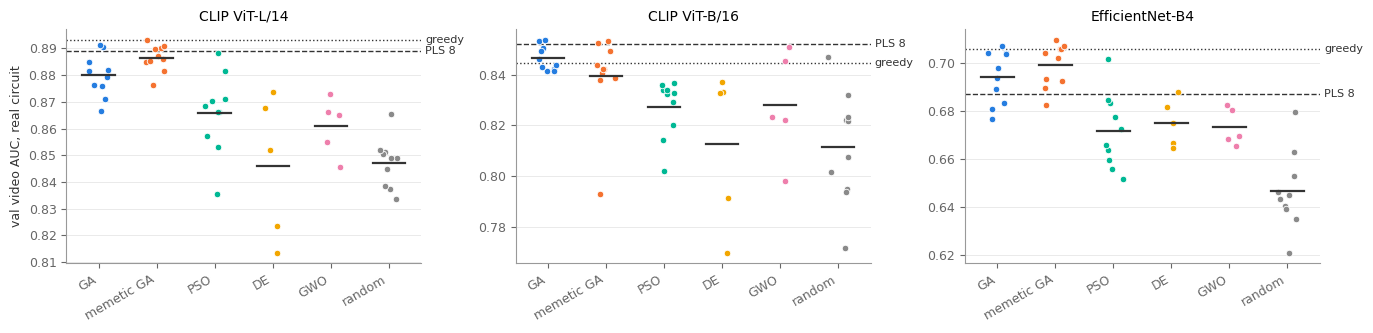

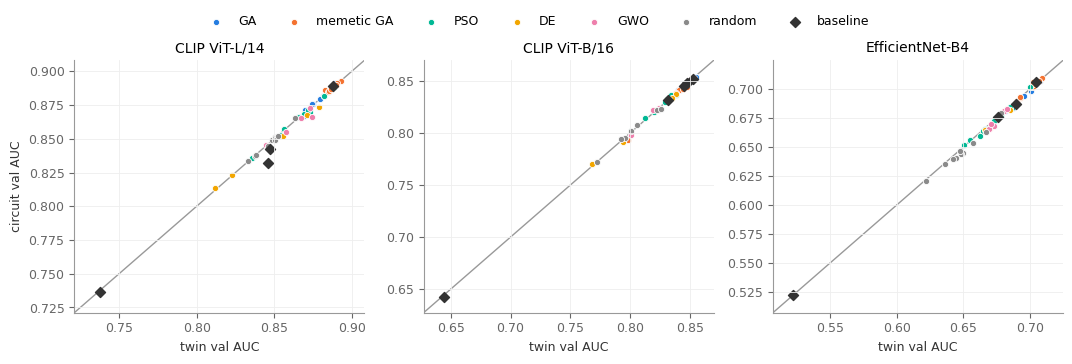

In [11]:
colors = {"GA": "#257de0", "memetic GA": "#f47230", "PSO": "#00b894", "DE": "#f2a600", "GWO": "#ee7fac",
          "random": "#8a8a8a"}
order = ["GA", "memetic GA", "PSO", "DE", "GWO", "random"]
titles = {"l14": "CLIP ViT-L/14", "b16": "CLIP ViT-B/16", "effb4": "EfficientNet-B4"}
plt.rcParams.update({"font.size": 9, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.edgecolor": "#999999", "axes.labelcolor": "#333333",
                     "xtick.color": "#666666", "ytick.color": "#666666"})


def reference_lines(ax, b):
    lines = [("PLS 8", "--", ref[(b, "baseline: PLS 8")]), ("greedy", ":", ref[(b, "baseline: greedy")])]
    low, high = ax.get_ylim()
    close = abs(lines[0][2] - lines[1][2]) < 0.04 * (high - low)
    top = max(lines, key=lambda t: t[2])[0]
    for label, style, v in lines:
        ax.axhline(v, color="#333333", linestyle=style, linewidth=1)
        nudge = (5 if label == top else -5) if close else 0
        ax.annotate(label, (1.0, v), xycoords=("axes fraction", "data"), xytext=(3, nudge),
                    textcoords="offset points", va="center", fontsize=8, color="#333333")


fig, axes = plt.subplots(1, len(backbones), figsize=(4.6 * len(backbones), 3.4), squeeze=False)
rng = np.random.default_rng(seed)
for ax, b in zip(axes[0], backbones):
    for i, m in enumerate(order):
        v = runs[(runs["backbone"] == b) & (runs["role"] == m)]["circuit val"].to_numpy()
        ax.scatter(i + rng.uniform(-0.18, 0.18, len(v)), v, s=22, color=colors[m], edgecolor="white",
                   linewidth=0.6, zorder=3)
        ax.plot([i - 0.28, i + 0.28], [v.mean(), v.mean()], color="#333333", linewidth=1.6, zorder=4)
    reference_lines(ax, b)
    ax.set_xticks(range(len(order)))
    ax.set_xticklabels(order, rotation=30, ha="right")
    ax.set_title(titles[b], fontsize=10)
    ax.grid(axis="y", color="#e6e6e6", linewidth=0.6)
axes[0][0].set_ylabel("val video AUC, real circuit")
plt.tight_layout()
plt.savefig(f"{out_dir}/circuit_val.png", dpi=200, bbox_inches="tight")
plt.show()

fig, axes = plt.subplots(1, len(backbones), figsize=(3.6 * len(backbones), 3.4), squeeze=False)
for ax, b in zip(axes[0], backbones):
    s = stage_a[stage_a["backbone"] == b].drop_duplicates("key")
    for m in order:
        t = s[s["role"] == m]
        ax.scatter(t["twin val"], t["circuit val"], s=20, color=colors[m], edgecolor="white", linewidth=0.6, label=m)
    t = s[s["role"].str.startswith("baseline")]
    ax.scatter(t["twin val"], t["circuit val"], s=26, color="#333333", marker="D", label="baseline")
    low = np.nanmin(s[["twin val", "circuit val"]].to_numpy()) - 0.015
    high = np.nanmax(s[["twin val", "circuit val"]].to_numpy()) + 0.015
    ax.plot([low, high], [low, high], color="#999999", linewidth=1, zorder=0)
    ax.set_xlim(low, high)
    ax.set_ylim(low, high)
    ax.set_title(titles[b], fontsize=10)
    ax.set_xlabel("twin val AUC")
    ax.grid(color="#eeeeee", linewidth=0.6)
axes[0][0].set_ylabel("circuit val AUC")
handles, labels = axes[0][0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", ncol=len(labels), frameon=False, bbox_to_anchor=(0.5, 1.07))
plt.tight_layout()
plt.savefig(f"{out_dir}/twin_vs_circuit.png", dpi=200, bbox_inches="tight")
plt.show()

## 11. Run log

In [12]:
info = {"finished": time.strftime("%Y-%m-%d %H:%M:%S"), "machine": machine_name, "smoke": smoke, "backbones": backbones,
        "seeds": seeds, "entanglers": entanglers, "lr": lr, "epochs": epochs, "batch_size": batch_size,
        "train_limit": train_limit, "n_boot": n_boot, "n_jobs": n_jobs, "trainings": int(len(trainings)),
        "mean_seconds_per_training": round(float(trainings["seconds"].mean()), 1),
        "total_minutes": round((time.time() - start_all) / 60, 1), "python": platform.python_version(),
        "numpy": np.__version__, "scipy": scipy.__version__, "sklearn": sklearn.__version__,
        "torch": torch.__version__, "pennylane": qml.__version__}
with open(f"{out_dir}/runs.jsonl", "a") as f:
    f.write(json.dumps(info) + "\n")
!ls -lh {out_dir}

total 568K
-rw-r--r-- 1 root root 128K Nov 26 18:36 circuit_val.png
-rw-r--r-- 1 root root 1.8K Nov 26 18:36 entangler_effect.csv
-rw-r--r-- 1 root root 1.7K Nov 26 18:36 finalists.csv
-rw-r--r-- 1 root root 7.0K Nov 26 18:36 finalists_val.csv
-rw-r--r-- 1 root root  468 Nov 26 18:36 runs.jsonl
-rw-r--r-- 1 root root  17K Nov 26 18:36 stage_a.csv
-rw-r--r-- 1 root root 1.7K Nov 26 18:36 stage_a_stats.csv
-rw-r--r-- 1 root root 2.4K Nov 26 18:36 stage_a_table.csv
-rw-r--r-- 1 root root  87K Nov 26 18:36 trainings.csv
-rw-r--r-- 1 root root 132K Nov 26 18:36 trainings.jsonl
-rw-r--r-- 1 root root  274 Nov 26 18:36 twin_vs_circuit.csv
-rw-r--r-- 1 root root 123K Nov 26 18:36 twin_vs_circuit.png
drwxr-xr-x 2 root root  36K Nov 26 18:36 weights
